# Musterlösung: Dixon-Auswertung und optionale B₀-Karte

Diese Lösung verwendet die bereitgestellten Wasser-/Öl-Beispieldaten auf einer gemeinsamen Schichtebene. Alle Rechenschritte und Kurzantworten sind ausgefüllt; die Ausgabe enthält auch den optionalen B₀-Teil.

Die tatsächlichen Echozeiten und Skalierungen stammen aus DICOM. Für den chemischen Abstand wird die **Skriptannahme von 3,5 ppm** verwendet, da kein gemessener Spektralabstand als Datei vorliegt. Das einfache Modell liefert lokale Signalanteile, keine validierte PDFF.

Die Ergebnisdateien dieser Musterlösung liegen unter **`ergebnisse/loesung/`**. Nach einer Änderung an Auswahl oder ROI sind die nachfolgenden Zellen erneut auszuführen.

**Schnittebene:** Die 20 bereitgestellten Bilder zeigen dieselbe leicht gekippte koronale Ebene als Längsschnitt durch die Flasche (512 × 512 Pixel, 10 mm Schichtdicke). Eine alternative sagittale Seitenansicht liegt in diesem Beispieldatensatz nicht vor. Die erste Bildanzeige unten verwendet die tatsächliche Dual-Echo-MR-Datei.

**0a · Bibliotheken installieren**

Führen Sie die folgende Codezelle mit **Shift + Enter** aus und warten Sie, bis die Installation abgeschlossen ist. Die Paketliste enthält die für das Praktikum benötigten Bibliotheken.

Starten Sie anschließend über **Kernel → Restart Kernel…** den Kernel neu und fahren Sie mit **Schritt 1** fort. Wenn die Bibliotheken bereits im gewählten Kernel installiert sind, können Sie diese Vorbereitungszelle überspringen.

In [1]:
%pip install -r requirements-jupyterhub.txt

Note: you may need to restart the kernel to use updated packages.


**0b · Bibliotheken laden**

Die Importe werden vor dem Laden der DICOM-Datei geprüft. Die Beispieldaten werden erst in Schritt 1 geöffnet. Der Ergebnisordner der Musterlösung wird separat angelegt.

In [2]:
from pathlib import Path
import numpy as np
import pydicom
import matplotlib.pyplot as plt
import mrt_hilfen as mh

Path("ergebnisse/loesung").mkdir(parents=True, exist_ok=True)
print("Bibliotheken geladen.")

Bibliotheken geladen.


**1 · Eine DICOM-Datei laden**

Die erste Datei ist vorgegeben: `daten/beispiel/wasser_oel_dual_echo2_magnitude.dcm` gehört zur Wasser-/Ölflasche ohne Metallknopf und enthält die Magnitude des zweiten Dual-Echos.
Anführungszeichen kennzeichnen den Dateipfad als Text. Die tatsächliche Echozeit lesen Sie anschließend aus den DICOM-Metadaten.

In [3]:
dicom = pydicom.dcmread("daten/beispiel/wasser_oel_dual_echo2_magnitude.dcm")

### So arbeiten Sie mit der Musterlösung

Führen Sie die Codezellen von oben nach unten aus. Die Voreinstellungen verwenden dieselbe Ebene und die dokumentierten Beispiel-ROIs. Die Lösung zeigt die Rechenwege und die Einschränkungen der Interpretation. Bei Änderungen an den Widgets müssen die folgenden Rechenzellen erneut ausgeführt werden.

**2 · Pixel auslesen**

`pixel_array` ist eine rechteckige Zahlentabelle (Array). `.shape` nennt Zeilen und Spalten.

In [4]:
pixelwerte = dicom.pixel_array
print(pixelwerte.shape)

(512, 512)


**3 · Das erste Bild**

Matplotlib zeichnet die gespeicherten Werte als Graustufen. Diese erste Ansicht ist noch nicht physikalisch skaliert.

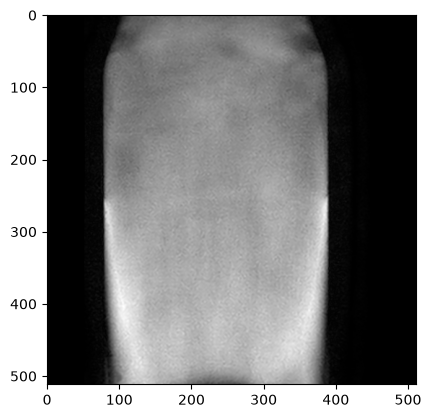

In [5]:
plt.imshow(pixelwerte, cmap="gray");

**4 · Tatsächliche Echozeit**

`float` macht aus dem DICOM-Wert eine Zahl. Lesen Sie `EchoTime` aus; Classic-DICOM speichert sie in Millisekunden.

In [6]:
te_ms = float(dicom.EchoTime)
print("Echozeit [ms]:", te_ms)

Echozeit [ms]: 13.8


**5 · Magnitude oder Phase?**

Geben Sie den Bildtyp aus. In diesen Dateien bedeutet `M` Magnitude und `P` Phase.

In [7]:
print(dicom.ImageType)

['ORIGINAL', 'PRIMARY', 'M_FFE', 'M', 'FFE']


**Kurzantwort: Bildtyp und TE**

Geladen ist die Magnitude des zweiten Dual-Echos (`ImageType` enthält `M`) mit TE = 13,8 ms. Die TE wird aus der Datei gelesen, nicht aus dem Dateinamen abgeleitet.

**6a · Rechnen ohne Ganzzahlüberlauf**

Wandeln Sie die Pixel in Gleitkommazahlen um. Sonst kann die spätere Subtraktion vorzeichenloser Ganzzahlen überlaufen.

In [8]:
pixel_float = pixelwerte.astype(float)

**6b · Skalierungsfaktoren lesen**

Slope und Intercept stehen in der Datei. Die Werte sind keine Konstanten für alle Scanner.

In [9]:
slope = float(dicom.RescaleSlope)
intercept = float(dicom.RescaleIntercept)

**6c · Skalierung anwenden**

Verwenden Sie $S=\mathrm{Pixel}\cdot\mathrm{Slope}+\mathrm{Intercept}$. Die Magnitude hat hier relative Signalwerte, keine Gewebekonzentration.

In [10]:
signal = pixel_float * slope + intercept
print("Signalbereich:", signal.min(), signal.max())

Signalbereich: 0.0 2104.6757020757


**7a · Ein Pixel**

Python beginnt bei Index 0. `signal[200, 250]` bedeutet Zeile 200, Spalte 250.

In [11]:
print("Pixel [200, 250]:", signal[200, 250])

Pixel [200, 250]: 1159.9882783882774


**7b · Einen Ausschnitt wählen**

`180:280` enthält Index 180 bis 279. Ergänzen Sie den Ausschnitt für Zeilen 180–279 und Spalten 210–289.

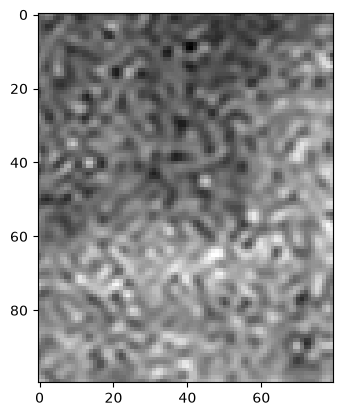

In [12]:
ausschnitt = signal[180:280, 210:290]
plt.imshow(ausschnitt, cmap="gray");

## Zwei passende Echos
Die Hilfsdatei übernimmt Dateisuche, Geometrieprüfung und Anzeige. Sie rechnet noch kein Dixon-Ergebnis aus.
Die Beispielauswahl enthält **20 DICOM-Bilder einer gemeinsamen Schichtebene**. Aufnahme, Echo und Bildtyp bleiben getrennte Merkmale.

Die Dateinamen benennen Objektzustand, Aufnahme, Echonummer und Bildtyp, z. B. `wasser_oel_dual_echo1_phase.dcm` oder `wasser_oel_mit_knopf_triple_echo3_magnitude.dcm`.
`echo1`, `echo2` und `echo3` zählen die Echos nach aufsteigender TE innerhalb der jeweiligen Aufnahme. Ob ein Echo IP oder OP ist, prüfen Sie anhand der tatsächlichen TE und des Frequenzabstands.

| Aufnahme | Echos | Bildtypen | Dateien |
| --- | --- | --- | ---: |
| Wasser/Öl · Dual-Echo | 1–2 | Magnitude und Phase | 4 |
| Wasser/Öl · Triple-Echo | 1–3 | Magnitude und Phase | 6 |
| Wasser/Öl mit Knopf · Dual-Echo | 1–2 | Magnitude und Phase | 4 |
| Wasser/Öl mit Knopf · Triple-Echo | 1–3 | Magnitude und Phase | 6 |

Die [Dateiübersicht](daten/beispiel/README.md) erläutert die Benennung. `manifest.csv` ordnet die neuen Dateinamen den ursprünglichen Exportnamen zu.
Die tatsächlichen TE, Bildtypen und Geometrien werden weiterhin aus den DICOM-Dateien gelesen.

**8a · Datenordner**

`daten/beispiel/` enthält die benannten Beispieldateien; `daten/eigene/` ist für Ihre Exporte vorgesehen.
Der Katalog behält nur Echobilder mit derselben Position, Orientierung, Pixelgröße und demselben Referenzrahmen wie die erste Datei.

In [13]:
datenordner = "daten/beispiel"
katalog = mh.katalog(datenordner, referenz=dicom)

**8c · Technische Übersicht**

Suchen Sie die Dual-Echo-Aufnahme und nennen Sie die beiden Magnituden-Echozeiten. Vollständige DICOM-Header gehören nicht in die Abgabe.

In [14]:
mh.uebersicht(katalog)

Datei,Aufnahme,Akq.,Typ,TE [ms],Position [mm]
wasser_oel_dual_echo1_magnitude.dcm,T1W_FFE dual echo,7,MAGNITUDE,6.901,"-64.87, -2.83, 56.33"
wasser_oel_dual_echo1_phase.dcm,T1W_FFE dual echo,7,PHASE,6.901,"-64.87, -2.83, 56.33"
wasser_oel_dual_echo2_magnitude.dcm,T1W_FFE dual echo,7,MAGNITUDE,13.8,"-64.87, -2.83, 56.33"
wasser_oel_dual_echo2_phase.dcm,T1W_FFE dual echo,7,PHASE,13.8,"-64.87, -2.83, 56.33"
wasser_oel_mit_knopf_dual_echo1_magnitude.dcm,T1W_FFE dual echo button,11,MAGNITUDE,6.901,"-64.87, -2.83, 56.33"
wasser_oel_mit_knopf_dual_echo1_phase.dcm,T1W_FFE dual echo button,11,PHASE,6.901,"-64.87, -2.83, 56.33"
wasser_oel_mit_knopf_dual_echo2_magnitude.dcm,T1W_FFE dual echo button,11,MAGNITUDE,13.8,"-64.87, -2.83, 56.33"
wasser_oel_mit_knopf_dual_echo2_phase.dcm,T1W_FFE dual echo button,11,PHASE,13.8,"-64.87, -2.83, 56.33"
wasser_oel_mit_knopf_triple_echo1_magnitude.dcm,T1W_FFE triple echo button,12,MAGNITUDE,9.201,"-64.87, -2.83, 56.33"
wasser_oel_mit_knopf_triple_echo1_phase.dcm,T1W_FFE triple echo button,12,PHASE,9.201,"-64.87, -2.83, 56.33"


**8d · Echo-Paar wählen**

Starten Sie mit `T1W_FFE dual echo`: frühes Echo als OP, spätes als IP. Das ist die Zuordnung des Beispielprotokolls; bei eigenen Daten anhand des Messprotokolls prüfen.

In [15]:
auswahl = mh.echo_auswahl(katalog, "T1W_FFE dual echo")

**8e · Ausgewählte Bilder übernehmen**

Nach einer Änderung im Auswahlfeld diese und alle folgenden Zellen erneut ausführen. Der Import skaliert jedes Bild genau einmal und prüft die Paarung.

In [16]:
op, ip, meta_op, meta_ip = mh.lade_paar(auswahl)

T1W_FFE dual echo | TE 6.901 / 13.8 ms | eine Ebene, 512 × 512 Pixel


**8f · Echozeiten nachsehen**

`meta_ip` und `meta_op` sind kleine Nachschlagewerke (Dictionaries); der Text in eckigen Klammern wählt den Eintrag.

In [17]:
print("OP [ms]:", meta_op["echozeit_ms"])
print("IP [ms]:", meta_ip["echozeit_ms"])

OP [ms]: 6.901
IP [ms]: 13.8


**9a · IP/OP physikalisch einordnen**

Nach dem Skript beträgt der chemische Abstand näherungsweise 3,5 ppm. Wir berechnen daraus mit der DICOM-Referenzfrequenz den Frequenzabstand in Hz. Falls ein gemessener Peakabstand vorliegt, ist dieser einzusetzen. Die Wasser-/Ölflasche wird hier im vereinfachten Ein-Peak-Modell betrachtet.

In [18]:
# 3,5 ppm gemäß Versuchsskript; die DICOM-Referenzfrequenz steht in MHz.
# ppm * MHz = Hz. Dies ist eine Skriptannahme, kein gemessener Peakabstand.
chemischer_shift_ppm = 3.5
chemie_hz = chemischer_shift_ppm * meta_ip["referenz_mhz"]
print("Chemischer Frequenzabstand aus Skriptannahme [Hz]:", chemie_hz)
print("Umdrehungen OP / IP:", np.array([meta_op["echozeit_ms"], meta_ip["echozeit_ms"]]) * chemie_hz / 1000)

Chemischer Frequenzabstand aus Skriptannahme [Hz]: 223.61361399999998
Umdrehungen OP / IP: [1.54315755 3.08586787]


**Kurzantwort: chemische Umdrehungen**

Mit der Skriptannahme ergeben sich ungefähr 1,543 Umdrehungen beim frühen und 3,086 beim späten Echo. Das liegt näherungsweise bei einer halben bzw. ganzen Zahl, ist aber nicht exakt OP bzw. IP. Diese Abweichung ist eine Grenze des vereinfachten Modells; der reale Peakabstand wurde hier nicht gemessen.

**9b · Gemeinsames Grauwertfenster**

Beide Bilder erhalten dasselbe Darstellungsfenster (0 bis gemeinsames 99. Perzentil). Die Arrays selbst werden nicht verändert oder einzeln normiert.

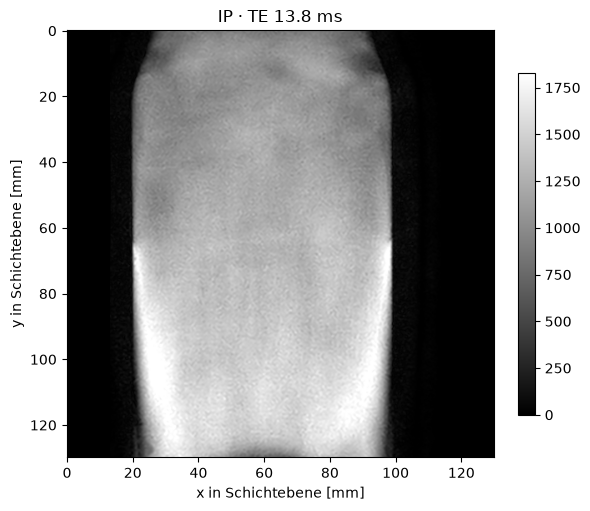

In [19]:
fenster = mh.fenster(ip, op)
fig_ip = mh.bild(ip, f"IP · TE {meta_ip['echozeit_ms']:g} ms", meta_ip, fenster)

**9c · OP vergleichen**

Vergleichen Sie dieselben Bildorte. Welche Bereiche verlieren im OP-Bild Signal?

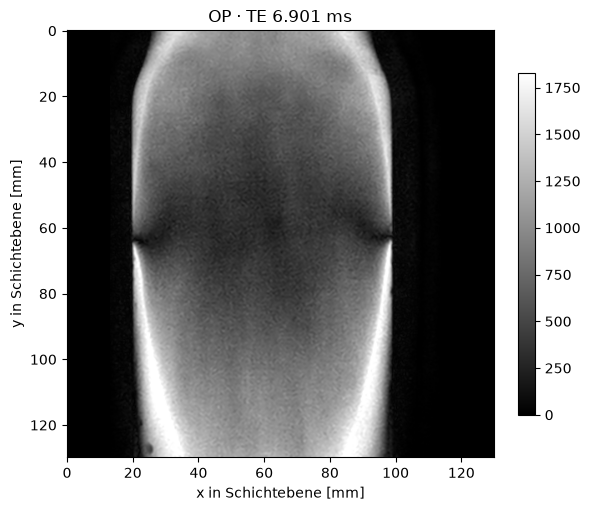

In [20]:
fig_op = mh.bild(op, f"OP · TE {meta_op['echozeit_ms']:g} ms", meta_op, fenster)

## Einfache Dixon-Rechnung
Im idealisierten Magnitudenmodell gilt $M_{IP}=W+F$ und $M_{OP}=|W-F|$.
Zunächst berechnen wir den **größeren** Anteil $A$ und den **kleineren** Anteil $B$.
Die Formel allein sagt noch nicht, welcher davon Wasser oder Fett ist.

**10 · Größeren Modellanteil berechnen**

Ergänzen Sie $A=(M_{IP}+M_{OP})/2$. Array-Rechnungen gelten gleichzeitig für jedes Pixel.

In [21]:
anteil_gross = (ip + op) / 2

**11 · Kleineren Modellanteil berechnen**

Ergänzen Sie $B=(M_{IP}-M_{OP})/2$. Verwenden Sie hier keinen Betrag und kein Clipping.

In [22]:
anteil_klein = (ip - op) / 2

**12a · Viereransicht**

Rote Pixel markieren negative kleinere Anteile. Dort ist das vereinfachte Modell verletzt, etwa durch Rauschen, Relaxation oder ein ungeeignetes Paar.

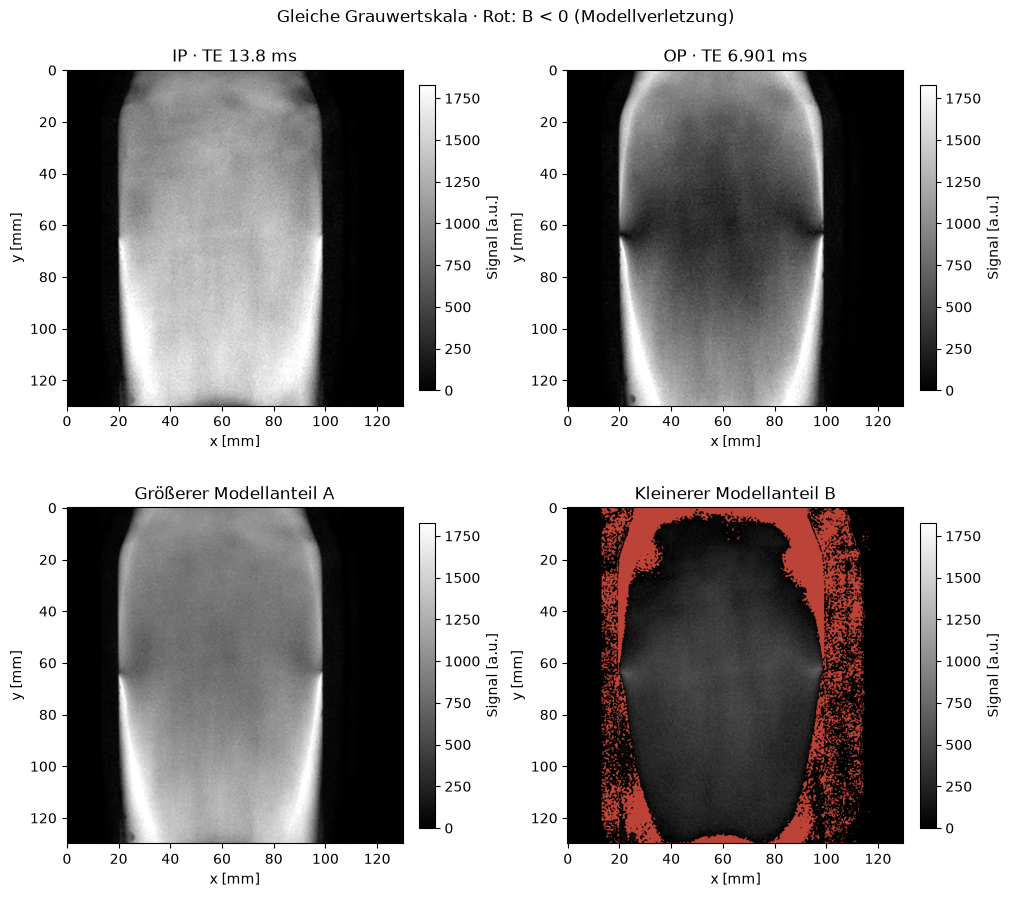

In [23]:
fig_dixon = mh.vierer(ip, op, anteil_gross, anteil_klein, meta_ip, meta_op)

**12b · Die Mehrdeutigkeit ausprobieren**

Ändern Sie anschließend die Werte zu Wasser = 20 und Fett = 80. Vergleichen Sie die Magnituden.

In [24]:
wasser_test, fett_test = 80, 20
print("Wasser 80 / Fett 20: IP / OP:", wasser_test + fett_test, abs(wasser_test - fett_test))
wasser_test, fett_test = 20, 80
print("Wasser 20 / Fett 80: IP / OP:", wasser_test + fett_test, abs(wasser_test - fett_test))

Wasser 80 / Fett 20: IP / OP: 100 60
Wasser 20 / Fett 80: IP / OP: 100 60


**Kurzantwort: Mehrdeutigkeit der Magnituden**

Beide Mischungen liefern IP = 100 und OP = 60. Der Betrag im OP-Bild entfernt das Vorzeichen von W − F; daher kann man Wasser und Fett vertauschen, ohne diese beiden Magnituden zu ändern. Für die lokale Zuordnung verwenden wir die bekannte Befüllung und Lagerung: im Wasserbereich W ≥ F, im Ölbereich F ≥ W.

**12c · Die bekannte Öl-Wasser-Flasche**

Die Zuordnung der Wasser- und Ölbereiche beruht auf der bekannten Befüllung und der dokumentierten Lagerung des Phantoms. Bei den Beispieldaten liegt in der dargestellten Ebene der ölreiche Bereich oben und der wasserreiche Bereich unten.

Die folgende Ansicht zeigt die geladene IP-Magnitude. Die Bildhelligkeit allein erlaubt keine eindeutige Wasser-/Fett-Zuordnung. Dokumentieren Sie bei eigenen Aufnahmen die Lage beider Flüssigkeiten und passen Sie die ROIs daran an.

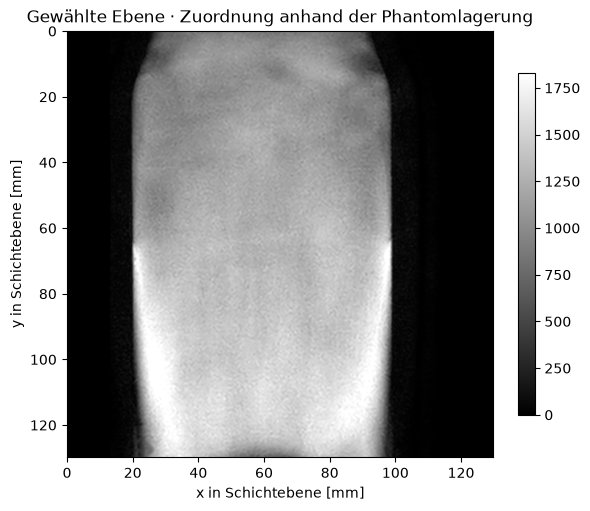

In [25]:
fig_zuordnung = mh.bild(ip, "Gewählte Ebene · Zuordnung anhand der Phantomlagerung", meta_ip, fenster)

## Interaktive ROI und Signalanteil
Eine **ROI** ist ein ausgewählter Bildbereich. Wir verwenden zuerst die markierte **Wasser-ROI**, danach die **Öl-ROI** derselben Ebene.
Die bekannte Befüllung und die dokumentierte Lagerung begründen die lokale Zuordnung: Wasser-ROI **W ≥ F**, Öl-ROI **F ≥ W**.
Die Schicht ist 10 mm dick; Übergangsbereiche können Partialvolumen enthalten. Die Signalanteile sind weder validierte PDFF noch exakte Volumenanteile.
Die vorgegebenen ROI-Koordinaten gelten für die Beispieldaten. Bei eigenen Daten die Bereiche anhand des eigenen Messprotokolls neu wählen.

**13a · Signalmaske**

Wir werten nur Pixel oberhalb von 15 % des 99. IP-Perzentils aus. Diese heuristische Schwelle ersetzt keine Rauschmessung. Ergänzen Sie den Vergleich `ip > schwelle`.

In [26]:
schwelle = 0.15 * np.percentile(ip, 99)
signalmaske = ip > schwelle

**13b · Wasser-ROI mit Schiebereglern wählen**

Starten Sie unten im wasserreichen Bereich: Zeilen 350:410, Spalten 310:360. Die grüne Fläche wird live aktualisiert; Rechteck und Signalmaske werden kombiniert.

In [27]:
roi_box = mh.roi_waehlen(ip, meta_ip, signalmaske)

**13c · Auswahl für die Rechnung übernehmen**

Diese Zelle kopiert den aktuellen ROI-Zustand. Nach jeder Regleränderung ab hier erneut ausführen; bereits berechnete Variablen ändern sich nicht rückwirkend.

In [28]:
roi = roi_box.maske
mh.pruefe_roi(roi)

3000 gültige Pixel, 1 zusammenhängende(r) Bereich(e).


**13d · Modellverletzungen zählen**

Negative Werte bleiben in der Rechnung enthalten. Ihr Anteil zeigt, wie kritisch das Ergebnis interpretiert werden muss.

In [29]:
negativ_prozent = 100 * np.mean(anteil_klein[roi] < 0)
print("ROI-Pixel mit B < 0 [%]:", negativ_prozent)

ROI-Pixel mit B < 0 [%]: 0.0


**14a · Wasser-ROI zuordnen**

In dieser Wasser-ROI ordnen wir unter **W ≥ F** den größeren Anteil dem Wasser zu. Die Zuordnung ist durch das Phantomwissen begründet und gilt nicht automatisch im ölreichen Bereich.

In [30]:
wasser = anteil_gross
fett = anteil_klein

**14b · ROI-Mittelwerte**

`array[roi]` wählt alle gültigen Pixel. Bildet deren Mittelwert. Ergänzen Sie beide Mittelwerte.

In [31]:
wasser_mittel = wasser[roi].mean()
fett_mittel = fett[roi].mean()

**15a · Bedingten Fett-Signalanteil berechnen**

Berechnen Sie $100\,\overline{F}/(\overline{W}+\overline{F})$. Das ist ein **Quotient von Mittelwerten**, kein Mittelwert pixelweiser Quotienten.

In [32]:
fett_signal_prozent = 100 * fett_mittel / (wasser_mittel + fett_mittel)
print("Fett-Signalanteil unter W ≥ F [%]:", fett_signal_prozent)

Fett-Signalanteil unter W ≥ F [%]: 17.420627531306735


**Kurzantwort: fettdominante Zuordnung und Belastbarkeit**

Bei umgekehrter Zuordnung tauschen größerer und kleinerer Modellanteil ihre Rollen. In derselben ROI würde der zugeordnete Fett-Signalanteil zu seinem Komplement wechseln. Der Wert hängt von der lokalen Annahme ab und ist wegen nicht idealer Echozeiten, Relaxation, Rauschen und Partialvolumen kein validierter Fett- oder Volumenanteil.

**Kurzantwort: Übergangsbereich**

Der kleinere Modellanteil ist zunächst nur min(W, F). In einer Übergangszone können Wasser und Öl innerhalb der 10-mm-Schicht gemischt sein; ihre Dominanz kann wechseln. Ohne örtliches Vorwissen lässt sich dieser Anteil dort nicht generell als Fett identifizieren. Negative Werte zeigen zusätzlich Verletzungen der Modellannahmen.

**15b · Ergebnisabbildung sichern**

Die Dateien landen im Ordner `ergebnisse/loesung`. Der ROI-Export zeigt die zuletzt gewählte grüne Fläche.

In [33]:
mh.speichere_bild(fig_dixon, "loesung/dixon.png")
mh.speichere_bild(roi_box.figure, "loesung/dixon_roi.png")

Gespeichert: ergebnisse/loesung/dixon.png
Gespeichert: ergebnisse/loesung/dixon_roi.png


**15c · ROI-Tabelle sichern**

Die Tabelle enthält Datei, TE, Position, ROI-Grenzen, gültige Fläche und Ergebnis mit der ausdrücklich benannten Zuordnungsannahme.

In [34]:
mh.protokoll("loesung/dixon_roi.csv", meta_op, meta_ip, roi_box,
             fett_unter_W_ge_F_prozent=fett_signal_prozent, negativ_prozent=negativ_prozent)

Gespeichert: ergebnisse/loesung/dixon_roi.csv


**15d · Jetzt die Öl-ROI wählen**

Wählen Sie oben den ölreichen Bereich: Zeilen 100:160, Spalten 120:170. Die Wasser-ROI bleibt separat gespeichert.

In [35]:
oel_box = mh.roi_waehlen(ip, meta_ip, signalmaske, start=(100, 160, 120, 170))

**15e · Öl-Auswahl übernehmen**

Nach Änderungen an diesem Regler ab hier erneut ausführen.

In [36]:
roi_oel = oel_box.maske
mh.pruefe_roi(roi_oel)

3000 gültige Pixel, 1 zusammenhängende(r) Bereich(e).


**15f · Die Zuordnung umkehren**

In der Öl-ROI gilt **F ≥ W**: Der größere Modellanteil gehört zum Fett-/Ölsignal, der kleinere zum Wassersignal. Ergänzen Sie die Mittelwerte in dieser ROI.

In [37]:
fett_oel_mittel = anteil_gross[roi_oel].mean()
wasser_oel_mittel = anteil_klein[roi_oel].mean()

**15g · Öl-ROI auswerten**

Berechnen Sie wieder den Quotienten der Mittelwerte. Vergleichen Sie das Ergebnis mit der Wasser-ROI.

In [38]:
fett_oel_prozent = 100 * fett_oel_mittel / (wasser_oel_mittel + fett_oel_mittel)
print("Fett-/Öl-Signalanteil unter F ≥ W [%]:", fett_oel_prozent)

Fett-/Öl-Signalanteil unter F ≥ W [%]: 83.8506992004587


**15h · Modellverletzungen in der Öl-ROI**

Auch hier negative kleinere Anteile weder abschneiden noch durch Beträge verstecken.

In [39]:
negativ_oel = 100 * np.mean(anteil_klein[roi_oel] < 0)
print("Öl-ROI: negative kleinere Anteile [%]:", negativ_oel)

Öl-ROI: negative kleinere Anteile [%]: 0.2


**15i · Öl-Ergebnis sichern**

Das zweite Ergebnis erhält einen eigenen Dateinamen und die andere Zuordnungsannahme.

In [40]:
mh.protokoll("loesung/dixon_oel_roi.csv", meta_op, meta_ip, oel_box,
             fett_unter_F_ge_W_prozent=fett_oel_prozent, negativ_prozent=negativ_oel)

Gespeichert: ergebnisse/loesung/dixon_oel_roi.csv


**15j · Beide Bereiche dokumentieren**

Speichern Sie auch die zweite markierte ROI für die Abgabe.

In [41]:
mh.speichere_bild(oel_box.figure, "loesung/dixon_oel_roi.png")

Gespeichert: ergebnisse/loesung/dixon_oel_roi.png


**Kurzantwort: bekannte Wasser- und Ölbereiche**

Für die voreingestellten ROIs mit jeweils 3000 Pixeln beträgt der bedingte Fett-Signalanteil **17,42 % in der Wasser-ROI** (W ≥ F) und **83,85 % in der Öl-ROI** (F ≥ W). Negative kleinere Modellanteile treten dort bei **0 % bzw. 0,2 %** der Pixel auf; sie wurden nicht abgeschnitten.

Die bekannte Phantomlagerung löst die Zuordnungsmehrdeutigkeit lokal auf: Im wasserreichen Bereich wird A dem Wasser zugeordnet, im ölreichen Bereich dem Öl. Die von 0 bzw. 100 % abweichenden Ergebnisse sind keine gemessenen Verunreinigungen; nicht ideale Echozeiten, Relaxation, Rauschen und Partialvolumen begrenzen das Modell. Eine passende Zuordnung allein belegt keine quantitative Stoffkonzentration.

## Zweite Aufnahme: Flasche mit Metallknopf

Für die Musterlösung stehen keine eigenen Messdaten zur Verfügung. Deshalb wird die im Aufgabenblatt vorgesehene zweite Beispielaufnahme `T1W_FFE dual echo button` auf derselben Ebene ausgewertet. Der Katalog enthält beide Aufnahmen; die Echos werden innerhalb der zweiten Aufnahme neu gepaart und ihre Geometrie wird geprüft.

Für einen direkten Vergleich werden dieselben ROI-Rechtecke und eine gemeinsame Grauwertskala verwendet. Die Signalmaske wird für die zweite Aufnahme neu berechnet. Die Lage der ROIs muss auch hier im angezeigten Bild kontrolliert werden; gleiche Geometrie allein garantiert bei bewegten Objekten keine identischen Objektbereiche.

T1W_FFE dual echo button | TE 6.901 / 13.8 ms | eine Ebene, 512 × 512 Pixel


3000 gültige Pixel, 1 zusammenhängende(r) Bereich(e).
2986 gültige Pixel, 1 zusammenhängende(r) Bereich(e).
TE mit Knopf [ms]: 6.901 13.8
Wasser-ROI: Fett-Signalanteil / negative Pixel [%]: 19.58737116049721 0.0
Öl-ROI: Fett-Signalanteil / negative Pixel [%]: 91.70773446200371 20.16075016744809


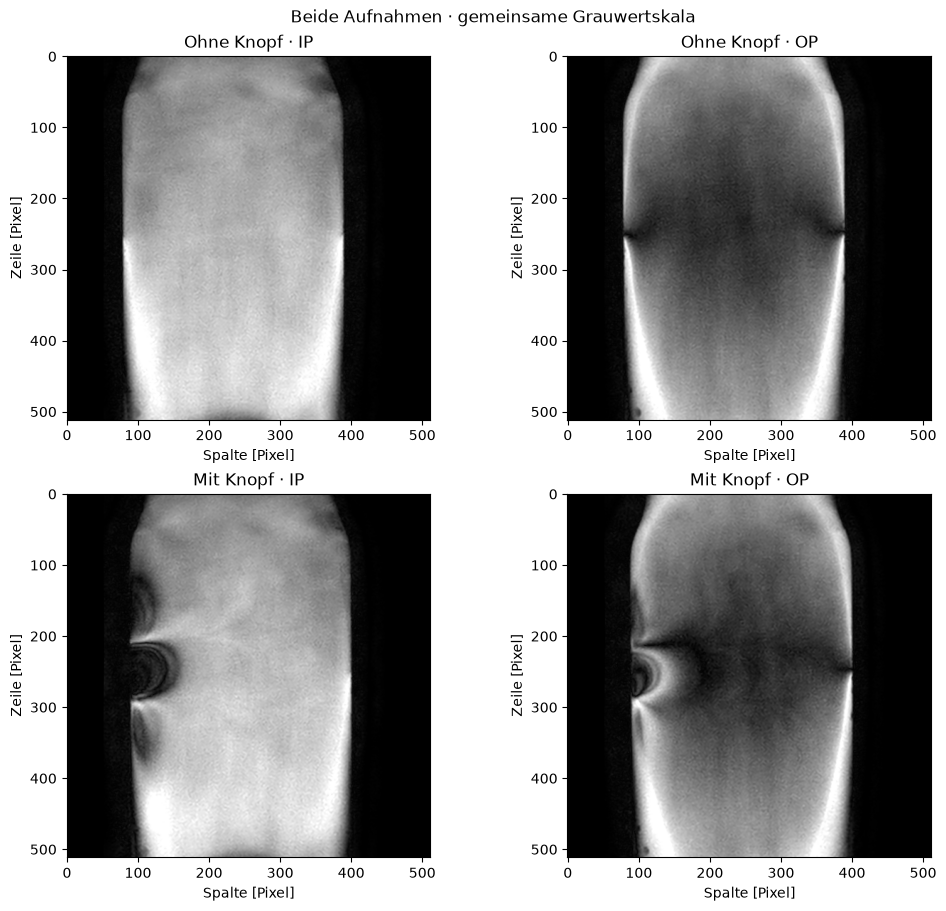

Gespeichert: ergebnisse/loesung/vergleich_knopf.png
Gespeichert: ergebnisse/loesung/knopf_wasser_roi.png


Gespeichert: ergebnisse/loesung/knopf_oel_roi.png
Gespeichert: ergebnisse/loesung/knopf_wasser_roi.csv
Gespeichert: ergebnisse/loesung/knopf_oel_roi.csv


In [42]:
button_auswahl = mh.echo_auswahl(katalog, "T1W_FFE dual echo button")
op_button, ip_button, meta_op_button, meta_ip_button = mh.lade_paar(button_auswahl)
assert mh.gleiche_geometrie(meta_ip, meta_ip_button)

gross_button = (ip_button + op_button) / 2
klein_button = (ip_button - op_button) / 2
signal_button = ip_button > 0.15 * np.percentile(ip_button, 99)
wasser_button_box = mh.roi_waehlen(ip_button, meta_ip_button, signal_button, start=roi_box.grenzen)
oel_button_box = mh.roi_waehlen(ip_button, meta_ip_button, signal_button, start=oel_box.grenzen)
roi_w_button = wasser_button_box.maske
roi_f_button = oel_button_box.maske
mh.pruefe_roi(roi_w_button)
mh.pruefe_roi(roi_f_button)

fett_w_button = 100 * klein_button[roi_w_button].mean() / ip_button[roi_w_button].mean()
fett_f_button = 100 * gross_button[roi_f_button].mean() / ip_button[roi_f_button].mean()
negativ_w_button = 100 * np.mean(klein_button[roi_w_button] < 0)
negativ_f_button = 100 * np.mean(klein_button[roi_f_button] < 0)
print("TE mit Knopf [ms]:", meta_op_button["echozeit_ms"], meta_ip_button["echozeit_ms"])
print("Wasser-ROI: Fett-Signalanteil / negative Pixel [%]:", fett_w_button, negativ_w_button)
print("Öl-ROI: Fett-Signalanteil / negative Pixel [%]:", fett_f_button, negativ_f_button)

vergleichsfenster = mh.fenster(ip, op, ip_button, op_button)
fig_vergleich, axes = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
for ax, bild, titel in zip(axes.ravel(), [ip, op, ip_button, op_button],
                          ["Ohne Knopf · IP", "Ohne Knopf · OP", "Mit Knopf · IP", "Mit Knopf · OP"]):
    ax.imshow(bild, cmap="gray", vmin=vergleichsfenster[0], vmax=vergleichsfenster[1])
    ax.set(title=titel, xlabel="Spalte [Pixel]", ylabel="Zeile [Pixel]")
fig_vergleich.suptitle("Beide Aufnahmen · gemeinsame Grauwertskala")
plt.show()
mh.speichere_bild(fig_vergleich, "loesung/vergleich_knopf.png")
mh.speichere_bild(wasser_button_box.figure, "loesung/knopf_wasser_roi.png")
mh.speichere_bild(oel_button_box.figure, "loesung/knopf_oel_roi.png")
mh.protokoll("loesung/knopf_wasser_roi.csv", meta_op_button, meta_ip_button, wasser_button_box,
             fett_unter_W_ge_F_prozent=fett_w_button, negativ_prozent=negativ_w_button)
mh.protokoll("loesung/knopf_oel_roi.csv", meta_op_button, meta_ip_button, oel_button_box,
             fett_unter_F_ge_W_prozent=fett_f_button, negativ_prozent=negativ_f_button)

**Kurzantwort: Vergleich der beiden Aufnahmen**

Mit Knopf ergeben sich für dieselben ROI-Rechtecke **19,59 %** Fett-Signalanteil im Wasserbereich und **91,71 %** im Ölbereich. Negative kleinere Modellanteile treten bei **0 % bzw. 20,16 %** der ausgewerteten Pixel auf. Besonders der Ölwert ist deshalb kritisch zu beurteilen: Der hohe Anteil negativer Pixel zeigt eine deutliche Verletzung des einfachen Modells. Die Signalmaske behält in dieser Öl-ROI 2986 statt 3000 Pixel.

Die zweite Aufnahme ist ein Vergleich unter veränderten Aufnahmebedingungen, keine bekannte quantitative Referenz. Die lokale Wasser-/Fett-Zuordnung bleibt durch die Phantomlagerung begründet. Abweichungen zwischen den ROI-Signalanteilen dürfen nicht als Änderung der Befüllung interpretiert werden. Der Bildvergleich zeigt am Metallknopf deutlichen Signalverlust und Verformungen; die innen gewählten ROIs beschreiben nur ihre jeweiligen lokalen Bereiche.

## Optional: Näherungsweise B₀-Karte
Wir verwenden **direkt exportierte Phasenbilder** der äußeren Triple-Echos, keine Real-/Imaginär-Rekonstruktion.
Diese Echos sind näherungsweise chemisch gleichphasig. Im Beispiel liegen drei chemische Umdrehungen zwischen ihnen;
ein exakt realisiertes 2π-/4π-Paar wird nicht vorausgesetzt.

Die Interpretation setzt konstante Empfangsphase, Objektlage, Shim und Frequenzeinstellung voraus.
Verwenden Sie für den Einstieg die signalstarke Wasser-ROI unten in der Flasche, nicht die Übergangszone.
Auch im wasserreichen Bereich bleibt die Karte eine Näherung; die gesamte Schicht wird nicht als reines Wasser behandelt.

**B1 · Phasenpaar wählen**

Die Voreinstellung verwendet die äußeren Triple-Echos `T1W_FFE triple echo`. Ein beliebiges IP-/OP-Phasenpaar ist für diese einfache B₀-Aufgabe ungeeignet.

In [43]:
phase_auswahl = mh.echo_auswahl(katalog, "T1W_FFE triple echo", modus="b0")

**B2 · Phasen laden**

Die Hilfsfunktion liest die Skalierung und Einheit aus DICOM, rechnet mrad in rad um und ordnet nach tatsächlicher TE.

In [44]:
phase_1, phase_2, meta_1, meta_2 = mh.lade_paar(phase_auswahl)

T1W_FFE triple echo | TE 9.201 / 23.001 ms | eine Ebene, 512 × 512 Pixel


**B3 · Tatsächliche TE übernehmen**

Lesen Sie die beiden Echozeiten selbst aus den Metadaten. Im Auswertecode werden keine Beispiel-Echozeiten eingetragen.

In [45]:
te_1_ms = meta_1["echozeit_ms"]
te_2_ms = meta_2["echozeit_ms"]

**B4 · TE kontrollieren**

Prüfen Sie Reihenfolge und Einheit vor der Division.

In [46]:
print("Echo 1 [ms]:", te_1_ms)
print("Echo 2 [ms]:", te_2_ms)

Echo 1 [ms]: 9.201
Echo 2 [ms]: 23.001


**B5 · Zeitabstand berechnen**

Subtrahieren Sie die tatsächlichen Echozeiten und rechnen Sie Millisekunden in Sekunden um.

In [47]:
delta_te_ms = te_2_ms - te_1_ms
delta_te_s = delta_te_ms / 1000

**B6 · Chemische Näherung prüfen**

Die Umdrehungszahl sollte ungefähr ganzzahlig sein.

In [48]:
print("ΔTE [s]:", delta_te_s)
print("Chemische Umdrehungen im Abstand:", chemie_hz * delta_te_s)

ΔTE [s]: 0.013800000000000002
Chemische Umdrehungen im Abstand: 3.0858678732000002


**B7 · Erste Phase anzeigen**

Die Originalskalierung des Exports wird verwendet. Eine willkürliche Normierung auf −π bis π wäre falsch.

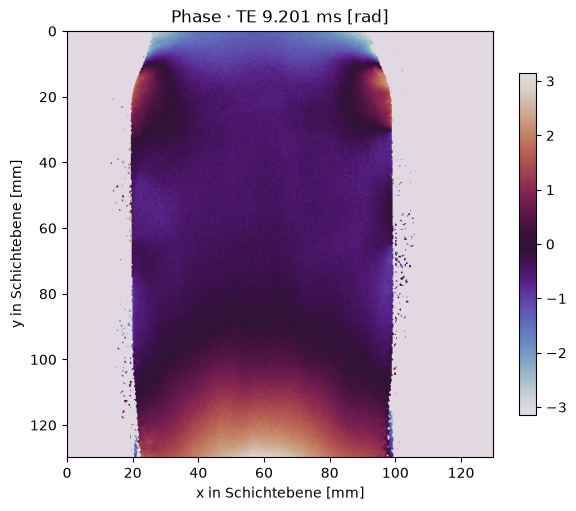

In [49]:
fig_phase_1 = mh.bild(phase_1, f"Phase · TE {te_1_ms:g} ms [rad]", meta_1, (-np.pi, np.pi), "twilight")

**B8 · Zweite Phase anzeigen**

Dieselbe Farbskala erlaubt den Vergleich. Die Außenbereiche sind verrauscht und werden für die Rechnung maskiert.

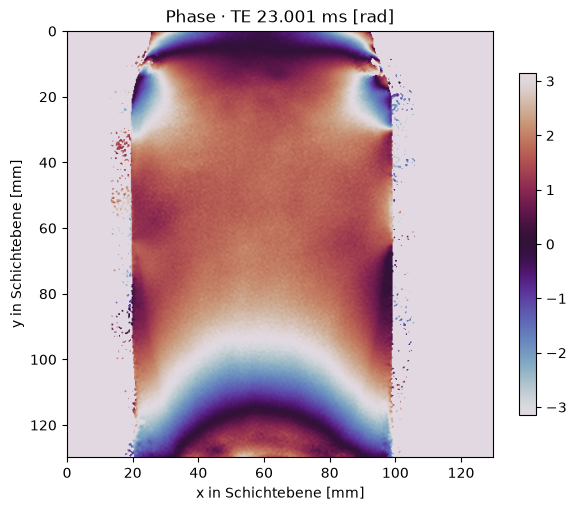

In [50]:
fig_phase_2 = mh.bild(phase_2, f"Phase · TE {te_2_ms:g} ms [rad]", meta_2, (-np.pi, np.pi), "twilight")

**B9 · Zugehörige Magnituden laden**

Für die Signalmaske benötigen wir Magnituden genau derselben Aufnahme, Ebene und Echozeiten wie die Phasen.

In [51]:
betrag_1 = mh.magnitude_zu_phase(katalog, meta_1)
betrag_2 = mh.magnitude_zu_phase(katalog, meta_2)

**B10 · Signal in beiden Echos verlangen**

Der Schwellwert wird für jedes Echo aus dessen 99. Perzentil bestimmt. `&` bedeutet: beide Bedingungen müssen stimmen. Erhöhen Sie bei Bedarf den Faktor.

In [52]:
schwellen_b0 = 0.15 * np.array([np.percentile(betrag_1, 99), np.percentile(betrag_2, 99)])
signal_b0 = (betrag_1 > schwellen_b0[0]) & (betrag_2 > schwellen_b0[1])

**B11 · Zusammenhängende innere ROI wählen**

Die grüne Fläche muss innerhalb eines signalstarken Objektbereichs liegen. Getrennte Teile können verschiedene unbekannte Phasenoffsets behalten.

In [53]:
b0_box = mh.roi_waehlen(betrag_1, meta_1, signal_b0)

**B12 · Maske übernehmen und prüfen**

Nach Regleränderungen ab dieser Zelle erneut ausführen. Bei mehreren getrennten Bereichen ein kleineres Rechteck im Objektinneren wählen.

In [54]:
maske_b0 = b0_box.maske
mh.pruefe_roi(maske_b0, zusammenhaengend=True)

3000 gültige Pixel, 1 zusammenhängende(r) Bereich(e).


**B13 · Zirkuläre Phasendifferenz**

Die vorbereitete Zeile berechnet $\arg\{\exp[i(\phi_2-\phi_1)]\}$. Sie entfernt Darstellungs-Sprünge einzelner Phasen, ist aber noch kein räumliches Unwrapping.

In [55]:
delta_phase = np.angle(np.exp(1j * (phase_2 - phase_1)))

**B14 · Maskiert entfalten**

Die bereitgestellte Funktion arbeitet nur innerhalb der geprüften ROI. Außerhalb steht NaN (kein gültiger Wert). Unwrapping bestimmt keinen absoluten globalen Offset.

3000 gültige Pixel, 1 zusammenhängende(r) Bereich(e).


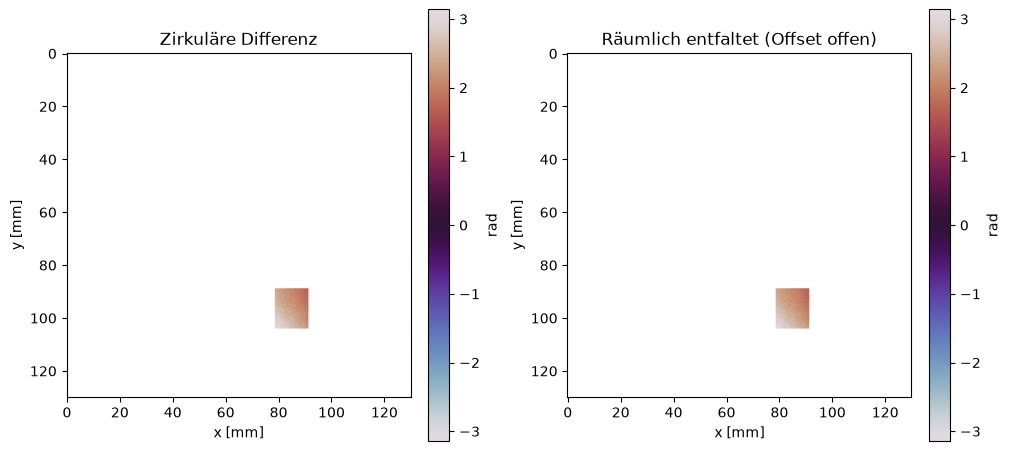

In [56]:
phase_entfaltet = mh.entfalte(delta_phase, maske_b0)
fig_entfaltet = mh.phasenvergleich(delta_phase, phase_entfaltet, maske_b0, meta_1)

**B15 · Von rad nach Hz**

Ergänzen Sie $\Delta f=\Delta\phi/(2\pi\,\Delta TE)$. Verwenden Sie den **gesamten** Echoabstand in Sekunden; kein zusätzlicher Faktor 1/2.

In [57]:
feld_hz = phase_entfaltet / (2 * np.pi * delta_te_s)

**B16 · Referenzfrequenz lesen**

Die DICOM-Frequenz steht in MHz. Rechnen Sie in Hz um; die Datei liefert die tatsächliche Frequenz.

In [58]:
referenz_hz = meta_1["referenz_mhz"] * 1e6
print("Referenzfrequenz [Hz]:", referenz_hz)

Referenzfrequenz [Hz]: 63889604.0


**B17 · Von Hz nach ppm**

Ergänzen Sie $\Delta B_0[\mathrm{ppm}]=10^6\,\Delta f/f_0$. Das Vorzeichen folgt hier der Konvention $\phi=\phi_0+2\pi\Delta f\,TE$; eine unabhängige Scanner-Vorzeichenkalibrierung liegt nicht vor.

In [59]:
feld_ppm = 1e6 * feld_hz / referenz_hz

**B18 · Nicht zentrierte Karte ansehen**

Titel und Maske machen die eingeschränkte Aussage sichtbar. Die Farbskala ist ±0,6 ppm; ändern Sie sie bei Sättigung für beide Karten gemeinsam.

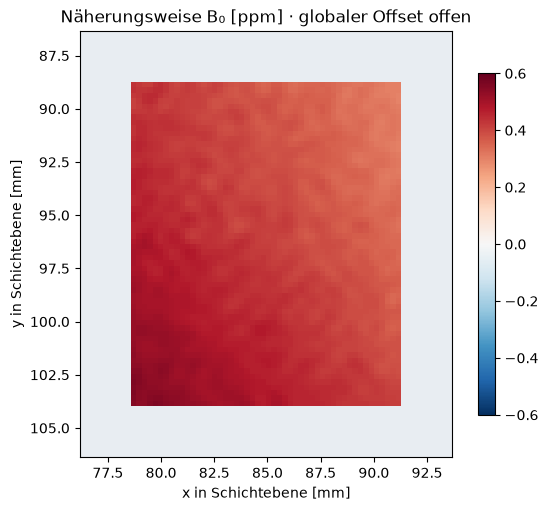

In [60]:
farbgrenze = 0.6
fig_b0 = mh.feldkarte(feld_ppm, maske_b0, meta_1, "Näherungsweise B₀ [ppm] · globaler Offset offen", farbgrenze)

**B19 · Relative Karte**

Ziehen Sie den ROI-Mittelwert ab. Ein gemeinsamer konstanter Offset spielt dann für die Homogenitätsmaße innerhalb dieser ROI keine Rolle.

In [61]:
offset_ppm = feld_ppm[maske_b0].mean()
feld_relativ = feld_ppm - offset_ppm

**B20 · Relative Homogenität darstellen**

Dies ist nur die ausgewählte ROI einer Schicht, keine Volumen-Homogenität. Ausgeblendete Pixel sind fehlende Information.

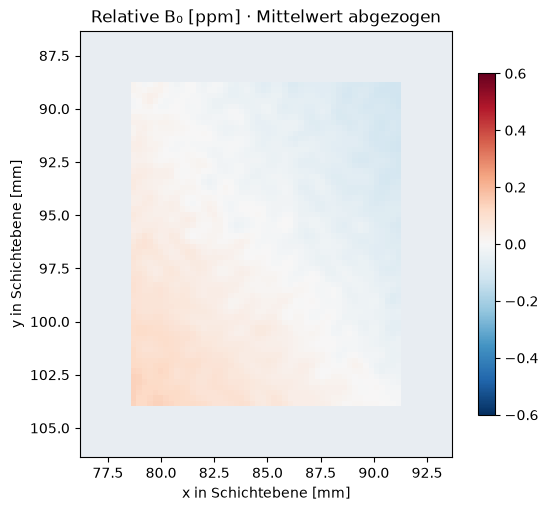

In [62]:
fig_b0_rel = mh.feldkarte(feld_relativ, maske_b0, meta_1, "Relative B₀ [ppm] · Mittelwert abgezogen", farbgrenze)

**B21 · Streuungsmaße**

Berechnen Sie Standardabweichung und Maximum minus Minimum. Peak-to-Peak reagiert empfindlich auf einzelne Ausreißer.

In [63]:
std_ppm = feld_relativ[maske_b0].std()
spanne_ppm = np.ptp(feld_relativ[maske_b0])

**B22 · Kennwerte ausgeben**

Berichten Sie auch den nicht absolut kalibrierten Mittelwert. Eine kleine Streuung allein beweist keine korrekte Feldrekonstruktion.

In [64]:
print("ROI-Mittel / Standardabweichung [ppm]:", offset_ppm, std_ppm)
print("Peak-to-Peak [ppm]:", spanne_ppm)

ROI-Mittel / Standardabweichung [ppm]: 0.4186355290222644 0.0537253052410379
Peak-to-Peak [ppm]: 0.25996393220436925


**B23 · Eindeutigkeitsgrenze**

Ohne zusätzliche Referenz gilt modulo $1/\Delta TE$. Das um null zentrierte Intervall liegt zwischen $-1/(2\Delta TE)$ und $+1/(2\Delta TE)$ (obere Grenze ausgeschlossen).

In [65]:
grenze_hz = 1 / (2 * delta_te_s)
print("Nicht entfaltetes Intervall: ±", grenze_hz, "Hz; ±", 1e6 * grenze_hz / referenz_hz, "ppm")

Nicht entfaltetes Intervall: ± 36.23188405797101 Hz; ± 0.5671014028819307 ppm


**Kurzantwort: Aussage der B₀-Karte**

Die tatsächlichen äußeren Echozeiten sind **9,201 und 23,001 ms**, also ΔTE = **13,8 ms**. In der voreingestellten Wasser-ROI mit 3000 Pixeln liefert der Durchlauf einen nicht absolut kalibrierten Mittelwert von **0,41864 ppm**, eine Standardabweichung von **0,05373 ppm** und Peak-to-Peak von **0,25996 ppm**. Nach Abzug des Mittelwerts bleiben beide Streuungsmaße gleich.

Die Karte beschreibt unter den Annahmen konstante Empfangsphase, gleiche Objektlage, Shim und Referenzfrequenz eine näherungsweise lokale Feldabweichung in dieser signalstarken Wasser-ROI. Ein globaler Offset bleibt offen. Die relative Karte und ihre Streuungsmaße gelten nur für die maskierte Fläche einer Ebene. Sie belegen weder eine absolute Feldkalibrierung noch die Homogenität des gesamten Volumens; chemische Restphase und Phasenrauschen bleiben mögliche Fehlerquellen.

**B24 · Abbildungen sichern**

Beide Karten verwenden dieselbe Farbgrenze. Speichern Sie zusätzlich die ROI-Ansicht.

In [66]:
mh.speichere_bild(fig_b0, "loesung/b0_nicht_zentriert.png")
mh.speichere_bild(fig_b0_rel, "loesung/b0_relativ.png")

Gespeichert: ergebnisse/loesung/b0_nicht_zentriert.png
Gespeichert: ergebnisse/loesung/b0_relativ.png


**B25 · Maske sichern**

Die ROI-Ansicht zeigt die ausgewertete Fläche innerhalb der ganzen Schicht.

In [67]:
mh.speichere_bild(b0_box.figure, "loesung/b0_roi.png")

Gespeichert: ergebnisse/loesung/b0_roi.png


**B26 · Tabelle sichern**

Die Tabelle dokumentiert die tatsächlichen Echos, ROI und maskiertes 2D-Unwrapping. Ein Funktionsaufruf darf innerhalb seiner Klammern über zwei Zeilen gehen.

In [68]:
mh.protokoll("loesung/b0_roi.csv", meta_1, meta_2, b0_box, delta_te_s=delta_te_s, offset_ppm=offset_ppm,
             std_ppm=std_ppm, peak_to_peak_ppm=spanne_ppm, unwrapping="maskiert_2D")

Gespeichert: ergebnisse/loesung/b0_roi.csv


## Abschluss der Musterlösung

**Ergebnis in zwei Sätzen:** Das IP-/OP-Magnitudenpaar liefert einen größeren und einen kleineren Signalanteil, deren Wasser-/Fett-Zuordnung erst mit bekanntem Phantomwissen in beiden ROIs möglich ist. Die äußeren Triple-Echos ermöglichen eine näherungsweise lokale B₀-Auswertung mit dokumentierter Maske, tatsächlichem Echoabstand und DICOM-Referenzfrequenz.

**Grenze der Interpretation:** Einfache Magnituden-Dixon-Anteile sind keine validierte PDFF; die Feldkarte hat einen offenen globalen Offset und ist auf die ausgewählte ROI einer Schicht begrenzt. Die Skriptannahme zum chemischen Frequenzabstand ersetzt keine Spektralmessung.

Die folgende Kontrolle prüft die Datenpaarung und die numerischen Ergebnisse des vollständigen Durchlaufs.

In [69]:
import json
import platform
from importlib.metadata import version
from datetime import datetime, timezone

assert len(katalog) == 20
assert ip.shape == op.shape == (512, 512)
assert meta_op["aufnahme"] == meta_ip["aufnahme"] == "T1W_FFE dual echo"
assert mh.gleiche_geometrie(meta_op, meta_ip)
np.testing.assert_allclose(anteil_gross + anteil_klein, ip)
np.testing.assert_allclose(anteil_gross - anteil_klein, op)
assert np.isfinite([wasser_mittel, fett_mittel, fett_signal_prozent, fett_oel_prozent]).all()
assert roi.sum() >= 16 and roi_oel.sum() >= 16
assert meta_1["aufnahme"] == meta_2["aufnahme"] == "T1W_FFE triple echo"
assert mh.gleiche_geometrie(meta_1, meta_2)
assert delta_te_s > 0
assert np.isfinite(feld_ppm[maske_b0]).all()
assert np.isnan(feld_ppm[~maske_b0]).all()
np.testing.assert_allclose(feld_relativ[maske_b0].mean(), 0, atol=1e-10)
np.testing.assert_allclose(std_ppm, feld_ppm[maske_b0].std())
assert spanne_ppm >= 0
assert grenze_hz > 0
assert meta_op_button["aufnahme"] == meta_ip_button["aufnahme"] == "T1W_FFE dual echo button"
assert mh.gleiche_geometrie(meta_op_button, meta_ip_button)
assert np.isfinite([fett_w_button, fett_f_button]).all()
np.testing.assert_allclose(gross_button + klein_button, ip_button)
np.testing.assert_allclose(gross_button - klein_button, op_button)

erwartete_dateien = ["dixon.png", "dixon_roi.png", "dixon_roi.csv", "dixon_oel_roi.csv", "dixon_oel_roi.png", "b0_nicht_zentriert.png", "b0_relativ.png", "b0_roi.png", "b0_roi.csv", "vergleich_knopf.png", "knopf_wasser_roi.png", "knopf_oel_roi.png", "knopf_wasser_roi.csv", "knopf_oel_roi.csv"]
for name in erwartete_dateien:
    assert (Path("ergebnisse/loesung") / name).is_file(), name

pruefbericht = {
    "status": "erfolgreich",
    "zeitpunkt_utc": datetime.now(timezone.utc).isoformat(),
    "python": platform.python_version(),
    "pakete": {name: version(name) for name in ["numpy", "matplotlib", "pydicom", "scipy", "scikit-image", "ipywidgets", "ipykernel"]},
    "dicom_bilder": len(katalog),
    "bildform": list(ip.shape),
    "dixon_te_ms": [meta_op["echozeit_ms"], meta_ip["echozeit_ms"]],
    "chemischer_shift_ppm_annahme": chemischer_shift_ppm,
    "chemischer_frequenzabstand_hz": float(chemie_hz),
    "wasser_roi_fett_signal_prozent": float(fett_signal_prozent),
    "oel_roi_fett_signal_prozent": float(fett_oel_prozent),
    "wasser_roi_negative_pixel_prozent": float(negativ_prozent),
    "oel_roi_negative_pixel_prozent": float(negativ_oel),
    "knopf_te_ms": [meta_op_button["echozeit_ms"], meta_ip_button["echozeit_ms"]],
    "knopf_wasser_roi_fett_signal_prozent": float(fett_w_button),
    "knopf_oel_roi_fett_signal_prozent": float(fett_f_button),
    "knopf_wasser_roi_negative_pixel_prozent": float(negativ_w_button),
    "knopf_oel_roi_negative_pixel_prozent": float(negativ_f_button),
    "b0_te_ms": [float(te_1_ms), float(te_2_ms)],
    "delta_te_s": float(delta_te_s),
    "b0_roi_pixel": int(maske_b0.sum()),
    "b0_offset_ppm": float(offset_ppm),
    "b0_std_ppm": float(std_ppm),
    "b0_peak_to_peak_ppm": float(spanne_ppm),
    "exportierte_dateien": erwartete_dateien,
}
Path("ergebnisse/loesung/pruefbericht.json").write_text(json.dumps(pruefbericht, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print(json.dumps(pruefbericht, indent=2, ensure_ascii=False))
plt.close("all")

{
  "status": "erfolgreich",
  "zeitpunkt_utc": "2026-11-04T22:38:34.481558+00:00",
  "python": "3.12.14",
  "pakete": {
    "numpy": "2.3.5",
    "matplotlib": "3.11.2",
    "pydicom": "3.0.2",
    "scipy": "1.18.1",
    "scikit-image": "0.26.0",
    "ipywidgets": "8.1.9",
    "ipykernel": "7.4.0"
  },
  "dicom_bilder": 20,
  "bildform": [
    512,
    512
  ],
  "dixon_te_ms": [
    6.901,
    13.8
  ],
  "chemischer_shift_ppm_annahme": 3.5,
  "chemischer_frequenzabstand_hz": 223.61361399999998,
  "wasser_roi_fett_signal_prozent": 17.420627531306735,
  "oel_roi_fett_signal_prozent": 83.8506992004587,
  "wasser_roi_negative_pixel_prozent": 0.0,
  "oel_roi_negative_pixel_prozent": 0.2,
  "knopf_te_ms": [
    6.901,
    13.8
  ],
  "knopf_wasser_roi_fett_signal_prozent": 19.58737116049721,
  "knopf_oel_roi_fett_signal_prozent": 91.70773446200371,
  "knopf_wasser_roi_negative_pixel_prozent": 0.0,
  "knopf_oel_roi_negative_pixel_prozent": 20.16075016744809,
  "b0_te_ms": [
    9.201,
    

### Quellen

- [pydicom: Rescale](https://pydicom.github.io/pydicom/stable/reference/generated/pydicom.pixels.apply_rescale.html) — Skalierung gespeicherter Pixelwerte.
- [SDCFlows: Phasendifferenz und Feldkarte](https://www.nipreps.org/sdcflows/2.12/methods.html) — Zusammenhang zwischen Phase, Echoabstand und Hz.
- [scikit-image: unwrap_phase](https://scikit-image.org/docs/stable/api/skimage.restoration.html#skimage.restoration.unwrap_phase) — maskiertes räumliches Unwrapping.
- [Dixon 1984](https://doi.org/10.1148/radiology.153.1.6089263) — ursprüngliche Methode; hier wird bewusst die vereinfachte Magnitudenübung verwendet.